# 从零理解与运行 Qi 2023 库存模型

这里每个小例子可逐格执行。完整实验已在 `results/standard`；大规模训练通过统一入口运行。V4现场校准是独立工程扩展，方法与限制见README及docs/现场代码修正_v4.md。所有生成数据明确是合成数据，不能用于声称重现京东原始数值。

先选择本项目的Python环境为Notebook内核。若从其他目录打开，先把下格的ROOT改为解压文件夹。

In [1]:
from pathlib import Path
import sys, os
ROOT = Path.cwd()
if not (ROOT / 'run_full.py').exists():
    raise RuntimeError('请将Notebook工作目录设为本项目根目录')
sys.path.insert(0, str(ROOT))
if os.name == 'nt': sys.path.insert(0, str(ROOT / '.vendor'))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'work' / 'notebook_cache'))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from inventory_full.core import label, advance


## 1. 先只做库存加减

`I`是净库存。`max(I,0)`取正库存，`max(-I,0)`取缺货量。持有1单位一天付h，缺1单位一天付b。积欠不会在第二天自动消失。

In [2]:
stock = np.array([10.0])
rows=[]
for day, (arrival, demand) in enumerate([(0,3),(0,5),(17,4),(0,2),(0,7),(0,6)]):
    stock, H, B, lost = advance(stock, np.array([arrival]), np.array([demand]), np.zeros(1), h=1,b=9)
    rows.append([day,arrival,demand,float(stock[0]),float(H[0]),float(B[0])])
display(pd.DataFrame(rows,columns=['day','arrival','demand','end_inventory','holding_cost','backlog_cost']))


,day,arrival,demand,end_inventory,holding_cost,backlog_cost
0,0,0,3,7.0,7.0,0.0
1,1,0,5,2.0,2.0,0.0
2,2,17,4,15.0,15.0,0.0
3,3,0,2,13.0,13.0,0.0
4,4,0,7,6.0,6.0,0.0
5,5,0,6,0.0,0.0,0.0


## 2. 闭式标签为什么是17

订单在第0天下达、第2天到货，下次到货第6天。当前订单控制第2—5天。α=9/(9+1)=0.9，floor(0.9×4)=3，因此覆盖至第5天的累计需求。27−10=17。

先用公式，再把0—35个单位逐一试一遍。枚举是这个小例子的独立检验；全局多订单检验在tests中使用线性规划。

In [3]:
d = np.array([3,5,4,2,7,6],float)
a_star = label(d, stock=10, lead=2, next_arrival=6, b=9,h=1)
def interval_cost(a):
    inv=10.0; total=0.0
    for t,dt in enumerate(d):
        if t==2: inv+=a
        inv-=dt
        total+=max(inv,0)+9*max(-inv,0)
    return total
grid = np.arange(36)
print('公式标签:',a_star,'枚举最优:',grid[np.argmin([interval_cost(a) for a in grid])])
assert interval_cost(a_star) == min(interval_cost(a) for a in grid)


公式标签: 17.0 枚举最优: 17


## 3. 从零看一次求导

设预测=参数w×输入x，损失=(预测−答案)²。对w求导得到2×(wx−答案)×x。导数为负说明w增加一点会让损失下降。PyTorch可自动求导，但它求的是你定义的损失，不能保证业务成本或测试效果一定改善。

In [4]:
import torch
w=torch.tensor(1.0,requires_grad=True)
x=torch.tensor(2.0); answer=torch.tensor(6.0)
loss=(w*x-answer)**2
loss.backward()
print('自动梯度:',w.grad.item(),'手算:',2*(w.item()*x.item()-answer.item())*x.item())
with torch.no_grad(): w -= 0.1*w.grad
print('更新参数:',w.item(),'更新后损失:',((w*x-answer)**2).item())


自动梯度: -16.0 手算: -16.0
更新参数: 2.5999999046325684 更新后损失: 0.6400002837181091


## 4. 查看真实生成的数据和模型结果

训练输入与未来标签分别保存。模型只接收INPUTS，不能把`actual_future`、`Lnext`等当作在线输入。

,series_id,day,demand,planned_promotion
0,0,0,33.0,0.0
1,0,1,65.0,1.0
2,0,2,74.0,0.0
3,0,3,112.0,1.0
4,0,4,39.0,0.0
5,0,5,49.0,0.0
6,0,6,44.0,0.0
7,0,7,23.0,0.0
8,0,8,42.0,0.0
9,0,9,97.0,0.0


{'n_samples': 56781, 'split_counts': {'train': 47806, 'val': 8975}, 'snapshot_dimensions': 132, 'known_future_plan_dimensions': 60, 'train_label_latest_day': 279, 'validation_label_latest_day': 329, 'purge': 'Whole forecast horizon must finish before next temporal split', 'state_policy': 'causal Normal behavior plus future-independent random stock augmentation', 'forks': 'encoder positions 20,24,28; shared decoder; calibration scale uses days0..119 only'}


,method,holding_cost,stockout_cost,total_cost,turnover_days,stockout_ratio,relative_gap_pct
0,OPT,1280.554036,44.589312,1325.143348,3.074285,0.012467,0.000000
1,E2E_RNN,1659.109161,382.964749,2042.073911,4.182670,0.081650,54.102114
2,BM1,1936.183264,197.360004,2133.543267,4.898227,0.049700,61.004715
3,BM2,2274.675218,109.705890,2384.381108,5.882006,0.026650,79.933825
4,Normal,2765.775696,48.831565,2814.607260,6.930809,0.013483,112.400210
5,Gamma,2692.916244,54.719916,2747.636160,6.772393,0.014850,107.346335
6,E2E_GBM,1528.486844,561.852892,2090.339736,3.844596,0.105750,57.744424


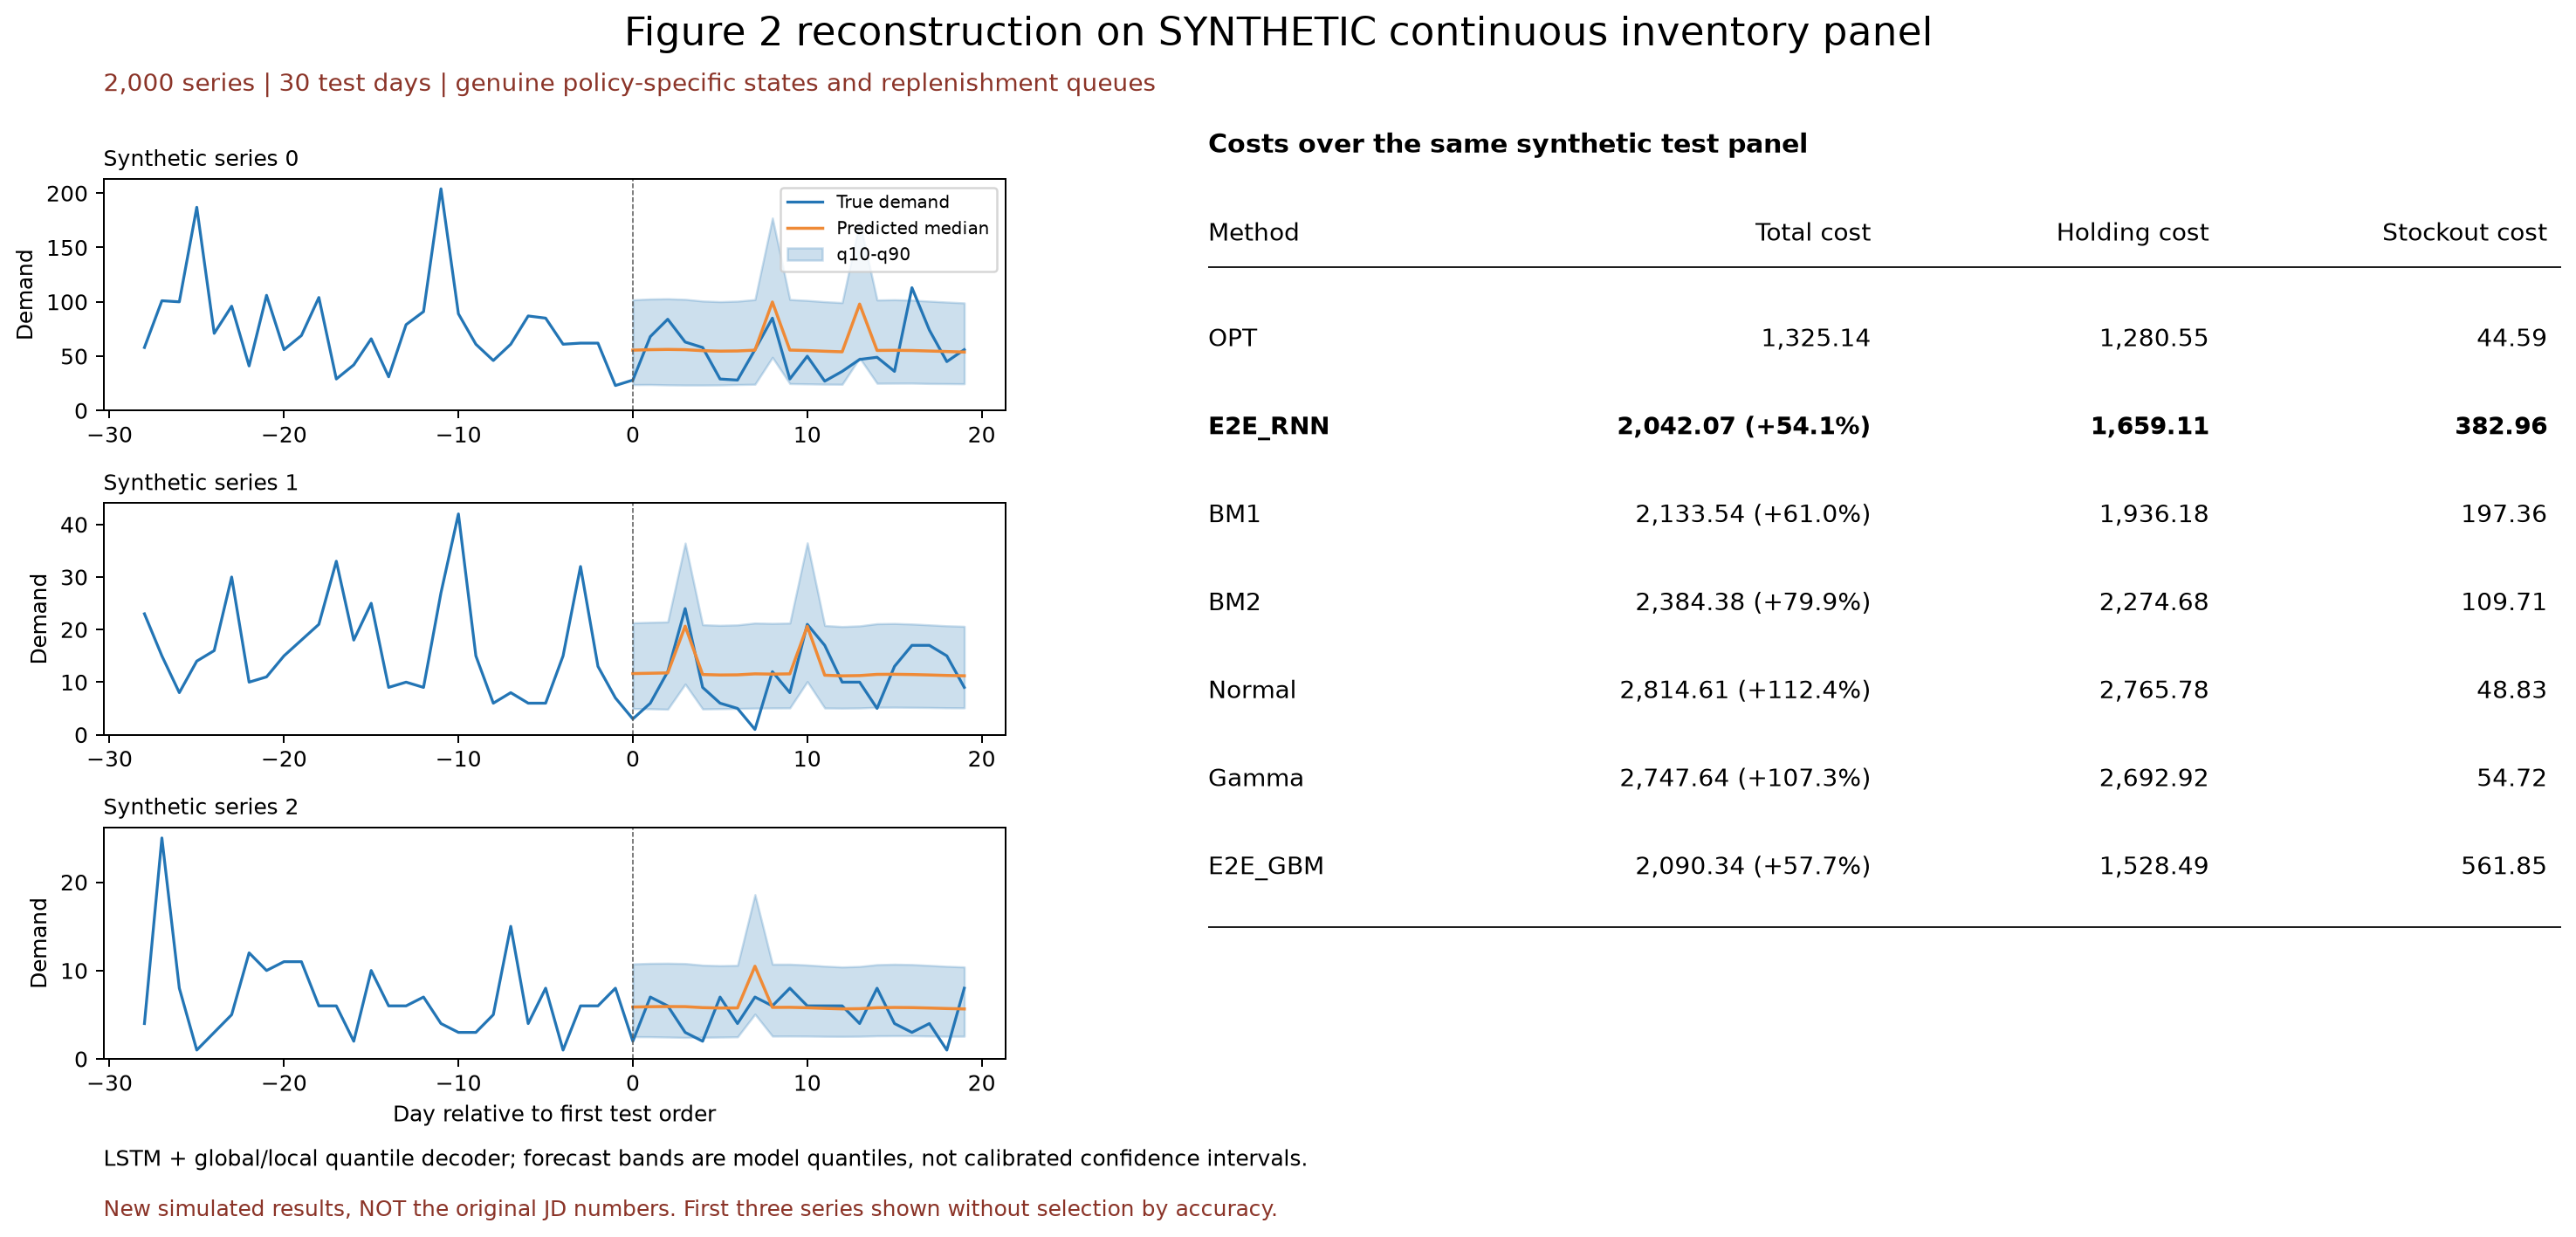

In [5]:
import json
profile='standard'
data=ROOT/'data'/profile
out=ROOT/'results'/profile
display(pd.read_csv(data/'daily_panel.csv.gz',nrows=12))
print(json.loads((data/'sample_audit.json').read_text('utf-8')))
display(pd.read_csv(out/'tables/costs_main.csv'))
display(Image(filename=str(out/'figures/figure2.png')))


## 5. 检查成本来自哪里

一行决策含订货量和到货日；每天都有需求、收货、净库存、持有及缺货成本。把每天的费用相加应与逐商品成本一致。

In [6]:
orders=pd.read_csv(out/'decisions/E2E_RNN_orders.csv.gz')
daily=pd.read_csv(out/'trajectories/E2E_RNN_daily.csv.gz')
display(orders[orders.series_id==0])
display(daily[daily.series_id==0].head(12))
cost0=daily.loc[daily.series_id==0,['holding_cost','stockout_cost']].sum().sum()
per=pd.read_csv(out/'tables/costs_by_series_main.csv')
expected=per.loc[(per.series_id==0)&(per.method=='E2E_RNN'),'total_cost'].iloc[0]
np.testing.assert_allclose(cost0,expected)
print('商品0的总成本核验:',cost0)


,method,series_id,order_day,arrival_day,order_quantity,net_stock_at_order,inventory_position
0,E2E_RNN,0,330,332,404.803741,268.866669,268.866669
2994,E2E_RNN,0,338,341,444.901917,259.670410,259.670410
5327,E2E_RNN,0,346,349,246.361313,345.572327,345.572327
7327,E2E_RNN,0,354,356,663.316406,-21.066360,-21.066360


,method,series_id,day,received,demand,end_inventory,holding_cost,stockout_cost,lost_sales,pending_after_day
0,E2E_RNN,0,330,0.000000,28.0,240.866669,240.866669,0.0,0.0,404.803741
2000,E2E_RNN,0,331,0.000000,68.0,172.866669,172.866669,0.0,0.0,404.803741
4000,E2E_RNN,0,332,404.803741,84.0,493.670410,493.670410,0.0,0.0,0.000000
6000,E2E_RNN,0,333,0.000000,63.0,430.670410,430.670410,0.0,0.0,0.000000
8000,E2E_RNN,0,334,0.000000,58.0,372.670410,372.670410,0.0,0.0,0.000000
10000,E2E_RNN,0,335,0.000000,29.0,343.670410,343.670410,0.0,0.0,0.000000
12000,E2E_RNN,0,336,0.000000,28.0,315.670410,315.670410,0.0,0.0,0.000000
14000,E2E_RNN,0,337,0.000000,56.0,259.670410,259.670410,0.0,0.0,0.000000
16000,E2E_RNN,0,338,0.000000,85.0,174.670410,174.670410,0.0,0.0,444.901917
18000,E2E_RNN,0,339,0.000000,29.0,145.670410,145.670410,0.0,0.0,444.901917


商品0的总成本核验: 11261.872116088867


## 6. 逐步重跑

下格默认不启动长训练。将RUN设为True即可运行快速版完整流程。使用`sys.executable`保证命令与Notebook是同一Python环境。完整标准版把quick改为standard；学习率、层数等实验通过sensitivity阶段自动重训。

In [7]:
import subprocess
RUN=False
if RUN:
    subprocess.run([sys.executable,'run_full.py','--profile','quick','--stage','all'],cwd=ROOT,check=True)


## 7. 附录与模拟现场

注意：p值显著不意味着模拟结果能代表京东。现场对照是Normal替代算法，供应商交叉到货是分布外压力测试。DID只在本生成与处理分配机制内解释。

,value,method,holding_cost,stockout_cost,total_cost,turnover_days,stockout_ratio,relative_gap_pct,train_seconds,training_series,training_samples,best_epoch
0,0.2,E2E_RNN,1748.588458,395.844197,2144.432656,4.333181,0.078283,61.826466,7.854122,400,9458,8
1,0.4,E2E_RNN,1611.007033,432.957499,2043.964532,4.073388,0.088100,54.244787,16.420762,800,19052,9
2,0.6,E2E_RNN,1680.549237,364.170490,2044.719727,4.261338,0.077200,54.301776,23.205477,1200,28582,6
3,0.8,E2E_RNN,1595.284378,436.081575,2031.365953,4.041848,0.089167,53.294054,30.452882,1600,38100,7
4,1.0,E2E_RNN,1659.109161,382.964749,2042.073911,4.182670,0.081650,54.102114,27.902116,2000,47806,6


,metric,treatment_pre,treatment_post,control_pre,control_post,did,standard_error_clustered,p_clustered
0,holding_cost,43631.365239,17940.075068,44846.276594,31934.414909,-12779.428487,1563.961038,3.053531e-16
1,stockout_cost,564.845301,28993.096030,672.317972,8142.857257,20957.711445,1500.954213,2.624372e-44
2,total_cost,44196.210540,46933.171098,45518.594567,40077.272167,8178.282958,1358.122282,1.725333e-09
3,turnover_days,7.748854,2.536563,7.868368,4.546106,-1.890029,0.161990,1.867184e-31
4,stockout_ratio,0.012139,0.264829,0.011024,0.092946,0.170768,0.007022,1.185692e-130


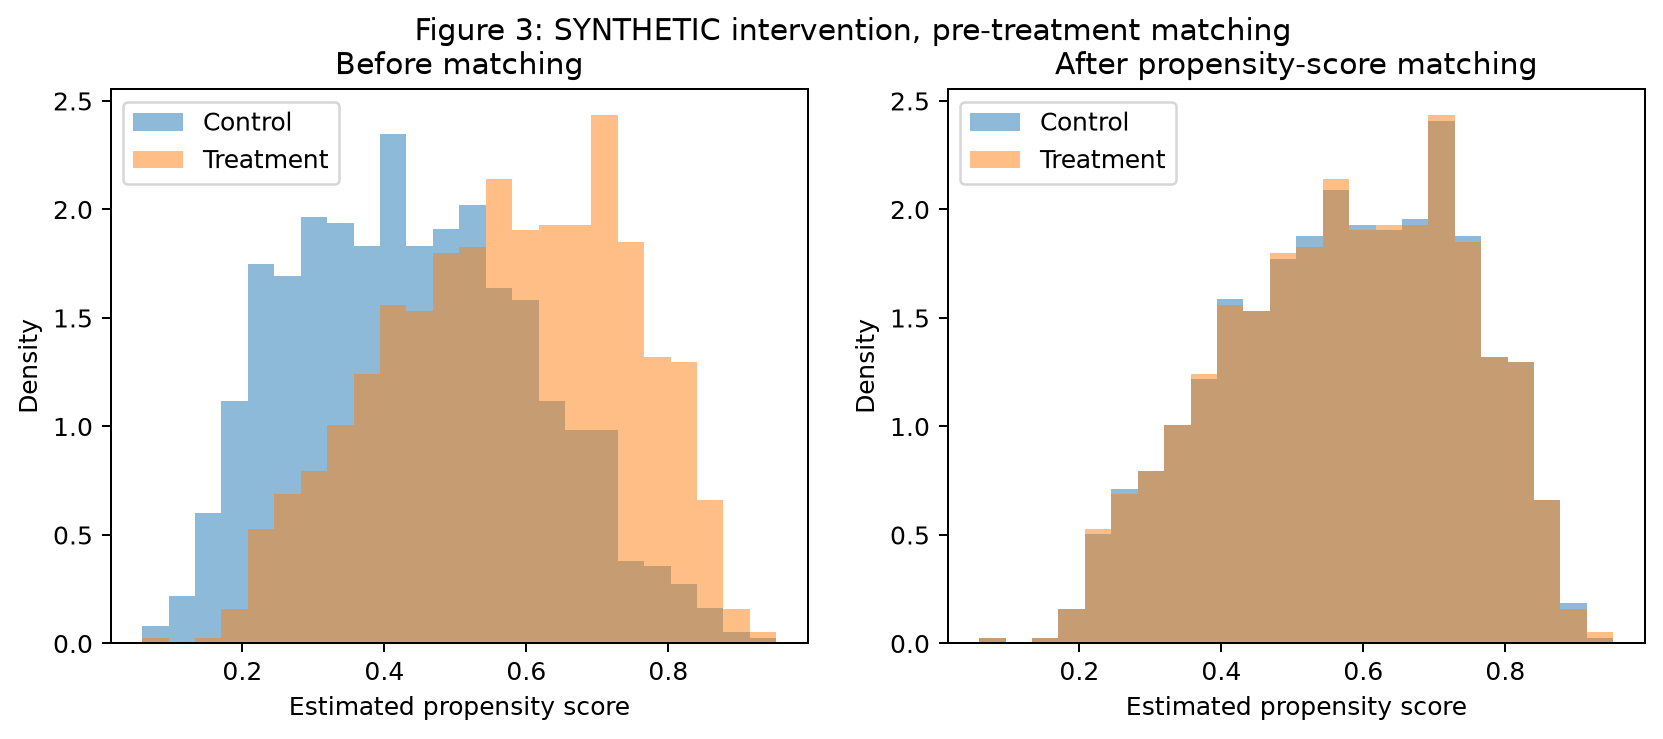

In [8]:
display(pd.read_csv(out/'tables/table_B5_data_size.csv'))
display(pd.read_csv(out/'tables/table4_synthetic_did.csv'))
display(Image(filename=str(out/'figures/figure3_matching.png')))
